# EDA — Fake.br-Corpus

Explora o `Fake.br-Corpus` (3.600 notícias falsas + 3.600 verdadeiras, **pareadas por tema**: a notícia falsa `N` e a verdadeira `N` tratam do mesmo assunto).

- `full_texts`: fonte principal (texto original, com maiúsculas, acentos e pontuação) e única versão com metadados.
- `size_normalized_texts`: em cada par, o texto mais longo é truncado para o tamanho do mais curto — usado para neutralizar o viés de comprimento.
- `preprocessed`: não usado (stopwords e acentos removidos, pensado para ML clássico, não para uso com LLM).

Dataset esperado em `../data/raw/Fake.br-Corpus/` (link simbólico para o clone local).

Definições das métricas usadas: [glossário](../references/glossario-metricas.md).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path("../data/raw/Fake.br-Corpus")
FULL_TEXTS_DIR = BASE_DIR / "full_texts"
NORM_TEXTS_DIR = BASE_DIR / "size_normalized_texts"
SEED = 42

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)

## 1. Carregamento dos dados

As datas dos metadados vêm em formatos misturados (`2017-11-30`, `13/12/2017`, `13/12/2017 14h32`, `13 de março de 2017`). Um `pd.to_datetime` genérico só entende parte deles, então o parser abaixo trata cada formato explicitamente e guarda o valor bruto em `data_bruta` para auditoria.

In [2]:
CAMPOS_META = [
    "autor", "link", "categoria", "data_bruta",
    "n_tokens", "n_palavras", "n_types", "n_links", "n_maiusculas",
    "n_verbos", "n_verb_subj_imp", "n_substantivos", "n_adjetivos",
    "n_adverbios", "n_verb_modais", "n_pron_1_2_sing", "n_pron_1_plural",
    "n_pronomes", "pausality", "n_caracteres", "comp_medio_sentenca",
    "comp_medio_palavra", "pct_erros_ortograficos", "emotiveness", "diversity",
]
CAMPOS_NUMERICOS = CAMPOS_META[4:]

MESES = {
    "janeiro": 1, "fevereiro": 2, "março": 3, "marco": 3, "abril": 4, "maio": 5, "junho": 6,
    "julho": 7, "agosto": 8, "setembro": 9, "outubro": 10, "novembro": 11, "dezembro": 12,
}


def parse_data(bruto: str) -> pd.Timestamp:
    if not isinstance(bruto, str):
        return pd.NaT
    s = bruto.strip().lower()
    padroes = [
        (r"(\d{4})-(\d{1,2})-(\d{1,2})", lambda m: (m[1], m[2], m[3])),
        (r"(\d{1,2})/(\d{1,2})/(\d{2,4})\b", lambda m: (m[3], m[2], m[1])),
        (r"(\d{1,2}) de ([a-zç]+) de (\d{4})", lambda m: (m[3], MESES.get(m[2]), m[1])),
    ]
    for padrao, extrair in padroes:
        m = re.search(padrao, s)
        if m:
            ano, mes, dia = extrair(m)
            if len(ano) == 2:
                ano = "20" + ano
            if not 1990 <= int(ano) <= 2030:
                return pd.NaT
            try:
                return pd.Timestamp(int(ano), int(mes), int(dia))
            except (TypeError, ValueError):
                return pd.NaT
    return pd.NaT


def carregar_textos(pasta: Path) -> pd.DataFrame:
    registros = []
    for arquivo in sorted(pasta.glob("*.txt"), key=lambda p: int(p.stem)):
        texto = arquivo.read_text(encoding="utf-8", errors="ignore")
        registros.append({"id": int(arquivo.stem), "texto": texto})
    return pd.DataFrame(registros)


def carregar_meta(pasta: Path) -> pd.DataFrame:
    registros = []
    for arquivo in pasta.glob("*-meta.txt"):
        linhas = [l.strip() for l in arquivo.read_text(encoding="utf-8", errors="ignore").splitlines()]
        registro = dict(zip(CAMPOS_META, linhas))
        registro["id"] = int(arquivo.stem.split("-")[0])
        registros.append(registro)
    df = pd.DataFrame(registros)
    df[CAMPOS_NUMERICOS] = df[CAMPOS_NUMERICOS].apply(pd.to_numeric, errors="coerce")
    df["data"] = df["data_bruta"].map(parse_data)
    return df


def carregar_classe(classe: str) -> pd.DataFrame:
    textos = carregar_textos(FULL_TEXTS_DIR / classe)
    meta = carregar_meta(FULL_TEXTS_DIR / f"{classe}-meta-information")
    df = textos.merge(meta, on="id", how="left")
    df["classe"] = classe
    return df


df = pd.concat([carregar_classe("fake"), carregar_classe("true")], ignore_index=True)
df["dominio"] = df["link"].str.extract(r"https?://(?:www\d?\.)?([^/]+)")[0]
df["n_palavras_texto"] = df["texto"].str.split().str.len()
df.shape

(7200, 31)

## 2. Estrutura e qualidade

In [3]:
nulos = df.drop(columns=["texto"]).isnull().groupby(df["classe"]).sum().T
print("Nulos por coluna e classe (só colunas com algum nulo):")
print(nulos[nulos.sum(axis=1) > 0])

Nulos por coluna e classe (só colunas com algum nulo):
classe   fake  true
n_links     0  1393
data        1     2


**Como ler:** ausente ([NaN/NaT](../references/glossario-metricas.md)) não é zero.

`n_links` nulo aparece só na classe `true`: o arquivo de metadados traz o texto literal `None` nesses casos, ou seja, o campo não foi coletado — não é o mesmo que "zero links". Não deve ser tratado como 0.

Datas: a taxa de sucesso do parser é conferida na seção 8.

In [4]:
duplicados = df[df["texto"].duplicated(keep=False)]
print(f"Linhas envolvidas em textos duplicados: {len(duplicados)}")
for _, linha in duplicados.iterrows():
    print(f"\n[{linha['classe']} #{linha['id']} | {linha['dominio']}]")
    print(linha["texto"][:300])

Linhas envolvidas em textos duplicados: 2

[true #61 | folha.uol.com.br]
Suplicy participará de programa de Doria na web nesta quinta

O vereador Eduardo Suplicy (PT-SP) participará nesta quinta-feira (10), às 20h30, do programa "Olho no Olho", transmitido pelas redes sociais do prefeito João Doria (PSDB-SP).

Doria já recebeu no quadro aliados e personalidades como o ca

[true #69 | g1.globo.com]
Suplicy participará de programa de Doria na web nesta quinta

O vereador Eduardo Suplicy (PT-SP) participará nesta quinta-feira (10), às 20h30, do programa "Olho no Olho", transmitido pelas redes sociais do prefeito João Doria (PSDB-SP).

Doria já recebeu no quadro aliados e personalidades como o ca


In [5]:
for classe in ["fake", "true"]:
    ids_meta = {int(p.stem.split("-")[0]) for p in (FULL_TEXTS_DIR / f"{classe}-meta-information").glob("*-meta.txt")}
    ids_texto = {int(p.stem) for p in (FULL_TEXTS_DIR / classe).glob("*.txt")}
    print(f"{classe}: metadados sem texto = {sorted(ids_meta - ids_texto)}; textos sem metadados = {sorted(ids_texto - ids_meta)}")

fake: metadados sem texto = []; textos sem metadados = []
true: metadados sem texto = []; textos sem metadados = []


**Como ler:** listas vazias `[]` = nenhum arquivo órfão.

## 3. Balanceamento de classes

In [6]:
print(df["classe"].value_counts())
print("\nPares completos (mesmo id nas duas classes):",
      len(set(df.loc[df.classe == 'fake', 'id']) & set(df.loc[df.classe == 'true', 'id'])))

classe
fake    3600
true    3600
Name: count, dtype: int64

Pares completos (mesmo id nas duas classes): 3600


**Como ler:** 3.600 × 3.600 = balanceado; todos os pares estão completos.

## 4. Leitura de amostras

Antes de qualquer estatística: ler textos reais de cada classe, procurando padrões que números não mostram (boilerplate de scraping, assinatura de veículo, formato de lead jornalístico).

In [7]:
for classe in ["fake", "true"]:
    print(f"{'=' * 30} {classe.upper()} {'=' * 30}")
    for _, linha in df[df["classe"] == classe].sample(4, random_state=SEED).iterrows():
        print(f"\n[#{linha['id']} | {linha['dominio']} | {linha['n_palavras_texto']} palavras]")
        print(linha["texto"][:500].replace("\n", " "))
    print()

============================== FAKE ==============================

[#1342 | diariodobrasil.org | 350 palavras]
Ataque biológico? Coreia do Norte descobre pandemia de vírus mortal e recusa ajuda.  País de Kim Jon-un luta contra um surto viral com o potencial de devastar a humanidade  e não permite ajuda externa.  De acordo com o britânico Daily Star, o país norte-coreano estaria lutando contra uma terrível gripe aviária. Ainda não foi descartada a tese de um suposto ataque biológico. Um surto, que também foi detectado em algumas cidades da China, já teria matado centenas de pessoas no norte da província 

[#1604 | diariodobrasil.org | 385 palavras]
Filho de Lula (aquele dos R$ 2,5 milhões) chama Bolsonaro de lixo e é humilhado nas redes sociais.  Luís Cláudio "Lulinha" quis assustar Jair Bolsonaro através das redes sociais e se deu mal.  O filho de Lula, Luís Claudio Lula da Silva (o Lulinha), postou em sua página no Facebook uma mensagem dizendo que a prisão de seu pai "tacaria fogo 

### 4.1 Frases repetidas (boilerplate de scraping)

Frases que se repetem idênticas em muitos documentos costumam ser rodapés, chamadas ou assinaturas do site coletadas junto com a notícia. Elas não dizem nada sobre veracidade, mas identificam o veículo — e um modelo aprende isso como atalho.

In [8]:
from collections import Counter


def frases(texto: str) -> list:
    partes = re.split(r"(?<=[.!?])\s+|\n+", texto.lower())
    return [p.strip() for p in partes if len(p.strip()) > 20]


LIMIAR_BOILERPLATE = 20
ocorrencias = Counter()
classe_da_frase = {}
for texto, classe in zip(df["texto"], df["classe"]):
    for frase in set(frases(texto)):
        ocorrencias[frase] += 1
        classe_da_frase.setdefault(frase, Counter())[classe] += 1

BOILERPLATE = sorted((f for f, n in ocorrencias.items() if n >= LIMIAR_BOILERPLATE), key=len, reverse=True)
print(f"Frases presentes em {LIMIAR_BOILERPLATE}+ documentos: {len(BOILERPLATE)}\n")
for frase, n in ocorrencias.most_common(15):
    if n < LIMIAR_BOILERPLATE:
        break
    print(f"{n:>5} docs {dict(classe_da_frase[frase])}  |  {frase[:100]}")

Frases presentes em 20+ documentos: 2

  112 docs {'true': 112}  |  aqui estão as principais notícias para você terminar o dia bem-informado.
   21 docs {'true': 21}  |  aqui estão as principais notícias para você começar o dia bem-informado..


**Como ler:** `nº de docs {classe: quantos} | frase`. Frase concentrada numa só classe = assinatura de veículo ([boilerplate](../references/glossario-metricas.md)).

## 5. Distribuição de comprimento de texto

Além das estatísticas descritivas, usa o teste de Mann-Whitney U (diferença entre distribuições, sem assumir normalidade) e o delta de Cliff (tamanho do efeito: -1 a 1, onde |δ| ≥ 0,474 é considerado efeito grande).

         count    mean    std   min    25%    50%     75%     max
classe                                                           
fake    3600.0   185.9  127.6   9.0  115.0  157.0   224.0  2288.0
true    3600.0  1100.3  683.0  20.0  642.0  918.0  1416.0  7517.0

 mediana_fake    157.0000
mediana_true    918.0000
cliffs_delta     -0.9616
p_valor           0.0000
dtype: float64


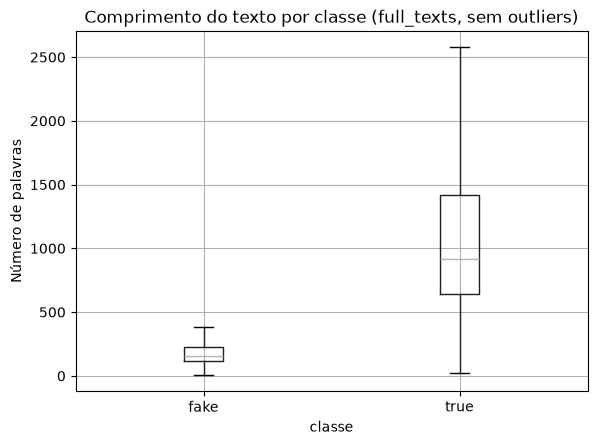

In [9]:
def cliffs_delta(a, b) -> float:
    u, _ = mannwhitneyu(a, b, alternative="two-sided")
    return 2 * u / (len(a) * len(b)) - 1


def comparar(coluna: str, dados: pd.DataFrame = df) -> dict:
    fake = dados.loc[dados["classe"] == "fake", coluna].dropna()
    true = dados.loc[dados["classe"] == "true", coluna].dropna()
    _, p = mannwhitneyu(fake, true, alternative="two-sided")
    return {"mediana_fake": fake.median(), "mediana_true": true.median(),
            "cliffs_delta": cliffs_delta(fake, true), "p_valor": p}


print(df.groupby("classe")["n_palavras_texto"].describe().round(1))
print("\n", pd.Series(comparar("n_palavras_texto")).round(4))

ax = df.boxplot(column="n_palavras_texto", by="classe", showfliers=False)
ax.set_title("Comprimento do texto por classe (full_texts, sem outliers)")
plt.suptitle("")
ax.set_ylabel("Número de palavras")
plt.show()

**Como ler:** compare as **medianas** (`50%`) e o **δ de Cliff**: negativo = true maior; |δ| ≥ 0,474 = efeito grande. O p-valor sozinho não serve aqui. Definições no [glossário](../references/glossario-metricas.md).

## 6. Vocabulário discriminativo (chi²)

`CountVectorizer(binary=True)`: cada termo vira presença/ausência por documento — o chi² foi desenhado para contagens, não para pesos TF-IDF. Como o chi² mede **força** de associação e não **direção**, o lado de cada termo é decidido pela proporção de documentos de cada classe em que ele aparece.

Rodado em `size_normalized_texts` para que textos mais longos não tenham mais chance de conter qualquer termo.

In [10]:
from nltk.corpus import stopwords

try:
    STOPWORDS_PT = stopwords.words("portuguese")
except LookupError as erro:
    raise RuntimeError(
        "Stopwords do NLTK não encontradas. Rode `make requirements` "
        "(baixa o recurso para .venv/nltk_data)."
    ) from erro

df_norm = pd.concat(
    [carregar_textos(NORM_TEXTS_DIR / "fake").assign(classe="fake"),
     carregar_textos(NORM_TEXTS_DIR / "true").assign(classe="true")],
    ignore_index=True,
)


def termos_discriminativos(textos: pd.Series, classes: pd.Series, top_n: int = 20) -> tuple:
    vetorizador = CountVectorizer(binary=True, ngram_range=(1, 2), min_df=5, stop_words=STOPWORDS_PT)
    X = vetorizador.fit_transform(textos)
    e_fake = (classes == "fake").to_numpy()
    scores, _ = chi2(X, e_fake)
    tabela = pd.DataFrame({
        "chi2": scores,
        "prop_fake": np.asarray(X[e_fake].mean(axis=0)).ravel(),
        "prop_true": np.asarray(X[~e_fake].mean(axis=0)).ravel(),
    }, index=vetorizador.get_feature_names_out())
    top_fake = tabela[tabela.prop_fake > tabela.prop_true].nlargest(top_n, "chi2")
    top_true = tabela[tabela.prop_true > tabela.prop_fake].nlargest(top_n, "chi2")
    return top_fake.round(3), top_true.round(3)


top_fake, top_true = termos_discriminativos(df_norm["texto"], df_norm["classe"])
print("Termos mais associados a FAKE:\n", top_fake)
print("\nTermos mais associados a TRUE:\n", top_true)

Termos mais associados a FAKE:
                   chi2  prop_fake  prop_true
através        208.642      0.081      0.009
dilma          200.205      0.217      0.087
disse          170.157      0.382      0.214
vídeo          161.281      0.137      0.047
pra            156.460      0.083      0.017
matéria        144.409      0.059      0.007
povo           144.048      0.077      0.016
hoje           134.615      0.194      0.091
jornalista     133.397      0.079      0.019
coréia         131.115      0.038      0.001
diário brasil  124.000      0.034      0.000
globo          114.618      0.078      0.021
coréia norte   114.131      0.033      0.001
poderá         108.478      0.084      0.026
diário         107.821      0.047      0.007
redes           98.430      0.096      0.036
redes sociais   97.506      0.088      0.031
site            95.629      0.056      0.013
esposa          95.438      0.041      0.006
tudo            90.705      0.124      0.057

Termos mais associados

**Como ler:** `chi2` = força da associação (sem lado); o lado é a maior entre `prop_fake` e `prop_true`. Ex.: `feira` 0,080 × 0,505 → associada a *true*. Termo discriminativo pode ser veículo, época ou estilo, não marca de mentira. Ver [glossário](../references/glossario-metricas.md).

## 7. Metadados estilométricos (normalizados)

Contagens absolutas (`n_maiusculas`, `n_pron_1_2_sing`) crescem com o tamanho do texto, e o texto verdadeiro é muito mais longo — comparar contagens brutas mede comprimento, não estilo. Por isso:

- contagens viram **taxa por 100 palavras**;
- `diversity` do metadado (razão type/token) cai naturalmente em textos longos, então é **recalculada** sobre `size_normalized_texts`, onde os pares têm o mesmo tamanho;
- `emotiveness`, `pausality`, `pct_erros_ortograficos` e comprimentos médios já são razões e são usados como vêm.

                        mediana_fake  mediana_true  cliffs_delta  p_valor
comp_medio_sentenca          15.0000       20.5858       -0.6228      0.0
pausality                     2.3397        2.9604       -0.4471      0.0
maiusculas_por_100            1.5873        0.9645        0.2569      0.0
pron_1_2_sing_por_100         0.0000        0.0000       -0.2038      0.0
ttr_normalizado               0.6487        0.6316        0.1203      0.0
comp_medio_palavra            4.8137        4.8672       -0.1120      0.0
pct_erros_ortograficos        0.0000        0.0013       -0.1089      0.0
emotiveness                   0.2000        0.2063       -0.0779      0.0


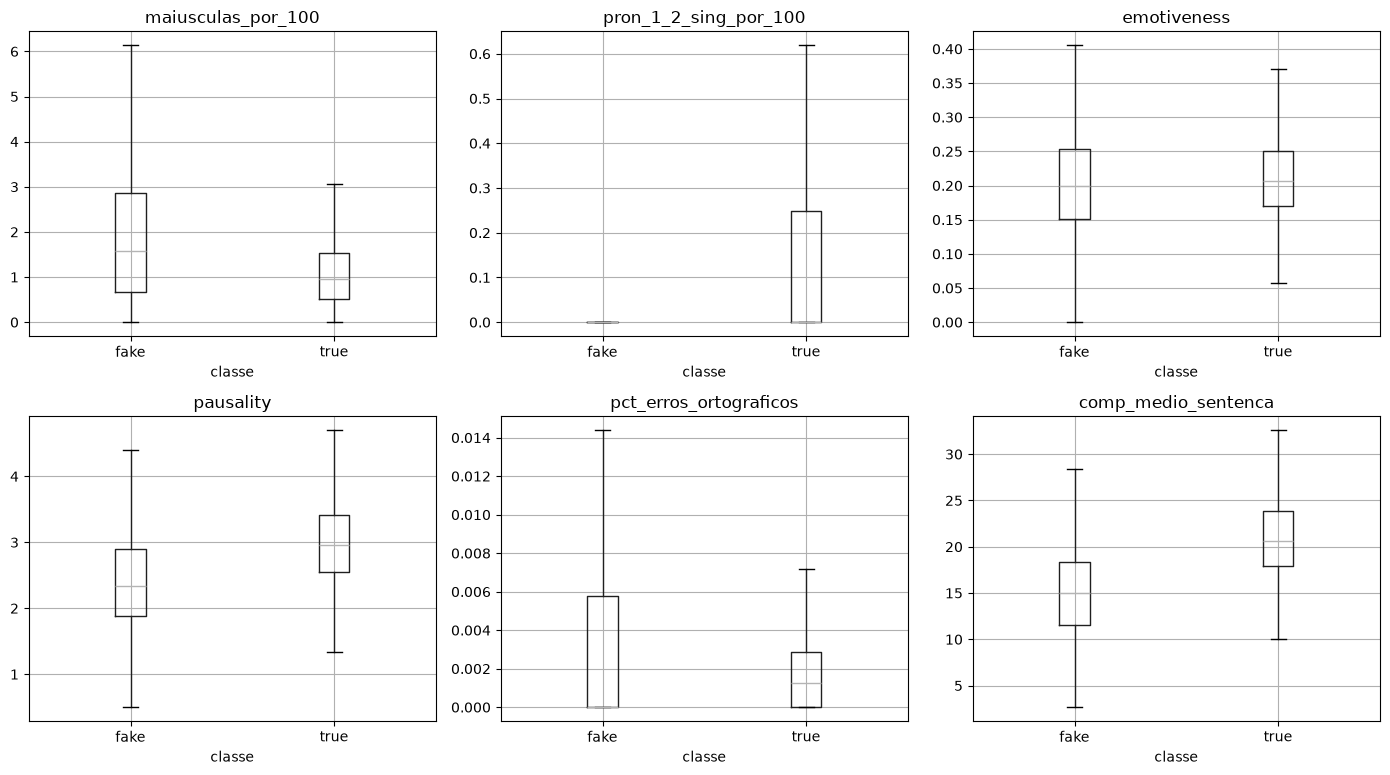

In [11]:
df["maiusculas_por_100"] = df["n_maiusculas"] / df["n_palavras"] * 100
df["pron_1_2_sing_por_100"] = df["n_pron_1_2_sing"] / df["n_palavras"] * 100


def type_token_ratio(texto: str) -> float:
    tokens = re.findall(r"\w+", texto.lower())
    return len(set(tokens)) / len(tokens) if tokens else np.nan


df_norm["ttr_normalizado"] = df_norm["texto"].map(type_token_ratio)

FEATURES_ESTILO = [
    "maiusculas_por_100", "pron_1_2_sing_por_100", "emotiveness", "pausality",
    "pct_erros_ortograficos", "comp_medio_sentenca", "comp_medio_palavra",
]
resultado = pd.DataFrame({coluna: comparar(coluna) for coluna in FEATURES_ESTILO}).T
resultado.loc["ttr_normalizado"] = comparar("ttr_normalizado", df_norm)
print(resultado.round(4).sort_values("cliffs_delta", key=abs, ascending=False))

colunas_plot = FEATURES_ESTILO[:6]
fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for coluna, eixo in zip(colunas_plot, eixos.flatten()):
    df.boxplot(column=coluna, by="classe", ax=eixo, showfliers=False)
    eixo.set_title(coluna)
plt.suptitle("")
plt.tight_layout()
plt.show()

**Como ler:** ordenado por |δ| — as primeiras linhas são as que mais diferenciam as classes. δ positivo = fake maior; negativo = true maior. Significado de cada métrica e escala do δ no [glossário](../references/glossario-metricas.md).

## 8. Distribuição temporal e por categoria

A categoria é **idêntica entre as classes por construção** (corpus pareado: a notícia falsa e a verdadeira de cada par têm o mesmo tema). Isso não é um achado, é uma propriedade do desenho do dataset — e uma boa: o tema está controlado.

In [12]:
taxa_parse = df.groupby("classe")["data"].apply(lambda s: s.notna().mean())
print("Taxa de datas interpretadas por classe:\n", taxa_parse.round(3))

nao_interpretadas = df.loc[df["data"].isna(), "data_bruta"]
print(f"\nDatas não interpretadas: {len(nao_interpretadas)}. Exemplos:")
print(nao_interpretadas.value_counts().head(10))

print("\nJanela temporal por classe:")
print(df.groupby("classe")["data"].agg(["min", "max", "median"]))

por_ano = df.dropna(subset=["data"]).groupby([df["data"].dt.year, "classe"]).size().unstack(fill_value=0)
print("\nNotícias por ano:\n", por_ano)

print("\nCategorias (idênticas por construção):")
print(df.groupby(["categoria", "classe"]).size().unstack())

Taxa de datas interpretadas por classe:
 classe
fake    1.000
true    0.999
Name: data, dtype: float64

Datas não interpretadas: 3. Exemplos:
data_bruta
03/09/0201    1
14/12/0201    1
6/1/0201      1
Name: count, dtype: int64

Janela temporal por classe:
              min        max     median
classe                                 
fake   2012-09-13 2018-02-02 2016-12-15
true   2009-06-01 2018-07-23 2017-10-10

Notícias por ano:
 classe  fake  true
data              
2009.0     0     3
2010.0     0     6
2011.0     0     5
2012.0     1     9
2013.0     0     5
2014.0     0    10
2015.0   235    40
2016.0  1586   278
2017.0  1608  2103
2018.0   169  1139

Categorias (idênticas por construção):
classe               fake  true
categoria                      
ciencia_tecnologia     56    56
economia               22    22
politica             2090  2090
religiao               22    22
sociedade_cotidiano   638   638
tv_celebridades       772   772


**Como ler:** taxa de datas interpretadas perto de 1,0 = análise temporal confiável. Classes concentradas em anos diferentes fazem termos da época virarem pista falsa. Categorias são iguais por construção.

## 9. Diversidade de fonte/domínio

Se cada classe vem de poucos veículos, um modelo pode aprender a reconhecer o **estilo do veículo** em vez da veracidade — um confundidor.

In [13]:
for classe in ["fake", "true"]:
    contagem = df.loc[df["classe"] == classe, "dominio"].value_counts()
    print(f"\n{classe}: {contagem.size} domínios distintos; o maior concentra {contagem.iloc[0] / contagem.sum():.1%}")
    print(contagem.head(8))


fake: 5 domínios distintos; o maior concentra 92.7%
dominio
diariodobrasil.org        3337
afolhabrasil.com.br        174
thejornalbrasil.com.br      66
ceticismopolitico.com       16
topfivetv.com                7
Name: count, dtype: int64

true: 24 domínios distintos; o maior concentra 63.9%
dominio
g1.globo.com                    2300
politica.estadao.com.br          753
internacional.estadao.com.br     114
cultura.estadao.com.br            95
folha.uol.com.br                  91
economia.estadao.com.br           51
brasil.estadao.com.br             46
esportes.estadao.com.br           30
Name: count, dtype: int64


**Como ler:** poucos domínios ou um domínio com mais de ~50% = o estilo desse site pode dominar o que um modelo aprende sobre a classe.

## 10. Checagens de robustez

### 10.1 A versão normalizada é mesmo igual par a par?

In [14]:
df_norm["n_palavras_texto"] = df_norm["texto"].str.split().str.len()
pares = df_norm.pivot(index="id", columns="classe", values="n_palavras_texto")
pares["diferenca"] = (pares["fake"] - pares["true"]).abs()
print(f"Pares com exatamente o mesmo número de palavras: {(pares['diferenca'] == 0).mean():.1%}")
print("Diferença absoluta por par (palavras):\n", pares["diferenca"].describe().round(2))

Pares com exatamente o mesmo número de palavras: 16.1%
Diferença absoluta por par (palavras):
 count    3600.00
mean        1.89
std         1.83
min         0.00
25%         1.00
50%         1.00
75%         3.00
max        20.00
Name: diferenca, dtype: float64


**Como ler:** mediana de 1–2 palavras = normalização funcionou (a diferença vem só da tokenização).

### 10.2 Quanto um classificador acerta usando atalhos?

Regressão logística com validação cruzada em 5 folds, agrupando pelo `id` do par (`GroupKFold`): as duas notícias de um mesmo par ficam sempre no mesmo fold, para o modelo não "ver" o tema no treino e reencontrá-lo no teste.

Cenários:

1. **Só comprimento** (`full_texts`): mede o quanto o tamanho sozinho denuncia a classe.
2. **Texto normalizado**: TF-IDF sobre `size_normalized_texts`.
3. **Texto normalizado mascarado**: mesmo cenário, mas com partes do texto apagadas (ver 10.2.1 abaixo). Se a acurácia cair pouco, o sinal não dependia dessas partes; se cair muito, dependia.
4. **Só estilo**: as features estilométricas normalizadas da seção 7.

#### 10.2.1 O que o mascaramento apaga

Antes de treinar o cenário 3, o texto é convertido para minúsculas e passa por quatro remoções:

| O que é apagado | Lista usada | Por quê |
|---|---|---|
| **Boilerplate** | frases idênticas presentes em 20+ documentos (seção 4.1) — ex.: "aqui estão as principais notícias para você terminar o dia bem-informado" | assinatura do site, não conteúdo |
| **Nomes de veículos** | g1, globo, rede globo, estadão, folha (de s. paulo), uol, diário do brasil, antagonista, afolhabrasil, thejornalbrasil, jornal brasil, ceticismo político, reuters, agência brasil, agência estado | revelam a fonte, que está concentrada por classe (seção 9) |
| **Marcadores de tempo** | nesta/neste, ontem, hoje, dias da semana, "feira", meses | padrão de lead jornalístico ("nesta quarta-feira") e pista de época |
| **Números** | qualquer sequência de dígitos (datas, anos, valores) | anos e datas denunciam a época da coleta |

**O que NÃO é apagado** (e por isso ainda pode ser usado pelo modelo): estilo de redação, vocabulário em geral, nomes de pessoas e eventos ("Dilma", "Lula", "Coreia do Norte"), pontuação.

Exemplos reais abaixo: o mesmo trecho antes e depois do mascaramento.

In [15]:
PADRAO_FONTES = (
    r"\b(g1|globo(\.com)?|rede globo|estad[ãa]o|folha( de s\.? ?paulo)?|uol|di[áa]rio do brasil|"
    r"diariodobrasil|antagonista|afolhabrasil|thejornalbrasil|jornal brasil|ceticismo pol[íi]tico|"
    r"reuters|ag[êe]ncia brasil|ag[êe]ncia estado)\b"
)
PADRAO_TEMPO = (
    r"\b(nest[ae]|ontem|hoje|segunda|ter[çc]a|quarta|quinta|sexta|s[áa]bado|domingo|feira|"
    r"janeiro|fevereiro|mar[çc]o|abril|maio|junho|julho|agosto|setembro|outubro|novembro|dezembro)\b"
)


def mascarar(texto: str) -> str:
    t = texto.lower()
    for frase in BOILERPLATE:
        t = t.replace(frase, " ")
    t = re.sub(PADRAO_FONTES, " ", t)
    t = re.sub(PADRAO_TEMPO, " ", t)
    t = re.sub(r"\d+", " ", t)
    return t


exemplos = [
    df_norm[(df_norm["classe"] == "true") & df_norm["texto"].str.contains(r"[Nn]esta \w+-feira")].iloc[0],
    df_norm[(df_norm["classe"] == "fake") & df_norm["texto"].str.contains("diário do brasil", case=False)].iloc[0],
]
for ex in exemplos:
    original = re.sub(r"\s+", " ", ex["texto"])[:350]
    mascarado = re.sub(r"\s+", " ", mascarar(ex["texto"]))[:350]
    print(f"[{ex['classe']} #{ex['id']}]\nORIGINAL:  {original}\nMASCARADO: {mascarado}\n")

[true #2]
ORIGINAL:  Em evento realizado nesta terça-feira para divulgar o Jogo das Estrelas, um amistoso beneficente que será realizado nesta quarta, no estádio do Maracanã, no Rio de Janeiro, Zico foi questionado sobre o ano do Flamengo. E o ídolo do clube não poupou críticas à montagem do elenco. "Minha visão é que alguns investimentos que foram feito não surtiram e
MASCARADO: em evento realizado - para divulgar o jogo das estrelas, um amistoso beneficente que será realizado , no estádio do maracanã, no rio de , zico foi questionado sobre o ano do flamengo. e o ídolo do clube não poupou críticas à montagem do elenco. "minha visão é que alguns investimentos que foram feito não surtiram efeito dentro do campo. acho que é u

[fake #308]
ORIGINAL:  Áudio de Lula mandando o MPF enfiar acervo da Presidência "naquele lugar" será enviado para a ONU. . Um grupo de aproximadamente 4 mil pessoas, incluindo juristas, advogados e profissionais liberais está preparando uma denúncia contra Lula na

**Como ler:** os espaços em branco no texto mascarado são onde havia veículo, data, número ou boilerplate. Tudo o que sobrou é o que o modelo do cenário 3 pode usar.

**Limitação:** o mascaramento é por lista de palavras, então às vezes apaga demais ("Rio de Janeiro" vira "rio de", porque "janeiro" está na lista de meses) e às vezes de menos (veículos fora da lista continuam). Serve como teste aproximado, não como remoção perfeita.

In [16]:
def avaliar(X, y, grupos, modelo) -> pd.Series:
    resultado = cross_validate(modelo, X, y, groups=grupos, cv=GroupKFold(n_splits=5),
                               scoring=["accuracy", "f1"])
    return pd.Series({"acuracia": resultado["test_accuracy"].mean(),
                      "f1": resultado["test_f1"].mean()})


def modelo_texto():
    return make_pipeline(
        TfidfVectorizer(min_df=5, ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(max_iter=2000),
    )


y_full = (df["classe"] == "fake").astype(int)
y_norm = (df_norm["classe"] == "fake").astype(int)
modelo_numerico = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

cenarios = {
    "1. só comprimento": avaliar(np.log1p(df[["n_palavras_texto"]]), y_full, df["id"], modelo_numerico),
    "2. texto normalizado": avaliar(df_norm["texto"], y_norm, df_norm["id"], modelo_texto()),
    "3. texto normalizado mascarado": avaliar(df_norm["texto"].map(mascarar), y_norm, df_norm["id"], modelo_texto()),
    "4. só estilo": avaliar(df[FEATURES_ESTILO].fillna(0), y_full, df["id"], modelo_numerico),
}
print(pd.DataFrame(cenarios).T.round(3))

                                acuracia     f1
1. só comprimento                  0.942  0.942
2. texto normalizado               0.923  0.923
3. texto normalizado mascarado     0.910  0.909
4. só estilo                       0.786  0.780


**Como ler:** 0,5 = chute. Cenário 1 alto = atalho de comprimento. Cenário 2 ≈ 3 = o sinal não depende dos marcadores removidos. Um modelo real precisa superar o cenário 1 com folga. Termos no [glossário](../references/glossario-metricas.md).

In [17]:
top_fake_masc, top_true_masc = termos_discriminativos(df_norm["texto"].map(mascarar), df_norm["classe"])
print("Termos mais associados a FAKE (mascarado):\n", top_fake_masc)
print("\nTermos mais associados a TRUE (mascarado):\n", top_true_masc)

Termos mais associados a FAKE (mascarado):
                   chi2  prop_fake  prop_true
através        208.642      0.081      0.009
dilma          200.205      0.217      0.087
disse          170.157      0.382      0.214
vídeo          161.281      0.137      0.047
pra            156.460      0.083      0.017
matéria        144.409      0.059      0.007
povo           144.048      0.077      0.016
jornalista     133.397      0.079      0.019
coréia         131.115      0.038      0.001
coréia norte   114.131      0.033      0.001
poderá         108.478      0.084      0.026
redes           98.430      0.096      0.036
redes sociais   97.506      0.088      0.031
site            95.629      0.056      0.013
esposa          95.438      0.041      0.006
tudo            90.705      0.124      0.057
petista         90.440      0.138      0.066
publicou        90.018      0.051      0.011
acordo          89.741      0.209      0.118
etc             88.926      0.029      0.001

Termos mai

**Como ler:** termo que **sumiu** em relação à seção 6 era atalho (veículo, data, boilerplate); o que **ficou** não dependia deles, mas ainda pode ser estilo de redação.

## 11. Síntese dos achados

**Qualidade**
- 7.200 textos, 3.600 pares completos, sem textos sem metadados. Classes perfeitamente balanceadas por construção.
- 1 texto duplicado dentro da classe `true` (#61 Folha e #69 G1): matéria de agência republicada por dois veículos. Irrelevante em volume, mas mostra que "fontes diferentes" nem sempre são independentes.
- `n_links` ausente (`None`) em 1.393 textos `true`: campo não coletado, não é zero.
- Datas: 99,9% interpretadas após tratar os 4 formatos. As 3 falhas são erros de digitação na própria fonte (ano `0201`).

**Confundidores — o ponto central deste dataset**
1. **Comprimento**: mediana de 157 palavras (fake) contra 918 (true), delta de Cliff = -0,96 (efeito máximo praticamente). **Só o comprimento classifica 94,2% dos textos corretamente** — mais do que o próprio texto normalizado (92,3%).
2. **Fonte**: 92,7% das fakes vêm de um único site (`diariodobrasil.org`); 63,9% das verdadeiras vêm do G1, o resto quase todo do Estadão.
3. **Convenções de redação jornalística**: os termos mais discriminativos de `true` são marcadores de agência ("nesta quarta-feira", "segundo", "presidente Luiz Inácio Lula", "Tribunal Regional Federal", "íntegra"), não conteúdo verdadeiro. Há também boilerplate de scraping do G1 ("aqui estão as principais notícias para você terminar o dia bem-informado", em pelo menos 133 textos) e do Estadão ("comentário Jornal Eldorado").
4. **Tempo**: fakes concentradas em 2016–2017 (mediana dez/2016); verdadeiras avançam por 2018 (mediana out/2017). Termos datados ("2017", "Dilma", "Coreia do Norte") carregam parte do sinal.

**Estilo (normalizado por tamanho)**
- Maior efeito: sentenças mais curtas nas fakes (15 contra 20,6 palavras; δ = -0,62) e menos pontuação por sentença (`pausality`, δ = -0,45).
- Fakes usam mais palavras em maiúscula por 100 palavras (δ = +0,26, efeito pequeno a médio) — confirma na direção a heurística de "maiúsculas" do prompt, mas o efeito é modesto.
- `emotiveness` e erros ortográficos praticamente não diferenciam (|δ| < 0,11). A intuição "fake é mais emotiva / mais mal escrita" **não se sustenta** neste corpus.
- Só com estilo, um classificador acerta 78,6%.

**Robustez**
- Mascarar veículos, datas, números e boilerplate derruba a acurácia só de 92,3% para 91,0%: o sinal não está só nesses marcadores. Mas o que sobra continua sendo, em boa parte, **registro de redação** (vocabulário de agência vs. de blog: "através", "pra", "matéria", "vídeo", "redes sociais" do lado fake), não veracidade. A máscara é parcial — resíduos como "boa noite" e "Eldorado" ainda passam.
- Na versão normalizada, 84% dos pares não têm exatamente o mesmo número de palavras pela tokenização simples usada aqui (diferença mediana de 1 palavra) — o corpus provavelmente usou outra tokenização para truncar, mas na prática os pares têm o mesmo tamanho.

**Implicações para o projeto**
- Uma acurácia alta neste dataset **não prova** que um modelo detecta desinformação: prova que ele distingue o estilo de um blog político de 2016 do estilo do G1/Estadão. Qualquer benchmark feito aqui precisa ser lido com isso em mente.
- Para o bot (LLM + busca de evidências, sem veredito binário), este corpus é mais útil como **fonte de exemplos reais de desinformação** (temas, narrativas, formas de apelo) do que como gabarito de avaliação.
- Se usado para few-shot, os exemplos `true` não devem ser escolhidos só entre leads de agência — senão o modelo associa "tom jornalístico" a verdade, o que é exatamente o viés que o projeto quer evitar.
- A comparação com o FakeTrue.Br (notebook 03) deve testar se esses padrões se repetem ou se são específicos da coleta deste corpus.
